# Data Preprocessing

**Project:** Predicting Post-Harvest Tomato Losses Among Nigerian Farmers Using Machine Learning

**Objective:** Prepare a reliable, clean dataset for machine-learning model development.

### Preprocessing stages
1. Define and validate the target variable.
2. Select relevant observations and features.
3. Investigate missing values.
4. Handle categorical and numerical variables.
5. Identify inconsistencies and potential outliers.
6. Prepare the final modelling dataset.
7. Export the processed dataset.

In [3]:
# Import pandas for dataset handling.
import pandas as pd

# Load the original, untouched dataset from the raw data folder.
df = pd.read_csv('tomato_endline-data.csv')

# Confirm that the dataset loaded successfully.
print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (928, 1949)


C:\Users\HomePC\AppData\Local\Temp\ipykernel_23372\1952670416.py:5: DtypeWarning: Columns (62,64,201,224,284,307,390,393,450,473,476,488,490,492,495,514,515,516,527,529,531,533,537,540,542,545,548,549,550,552,869,1032,1115,1130,1156,1157,1158,1169,1171,1173,1175,1179,1187,1190,1191,1194,1197) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('tomato_endline-data.csv')


In [4]:
# Compare the two main irrigated loss variables as potential
# prediction targets. This checks their distributions and
# data quality without modifying the original dataset.

target_candidates = [
    'farmLoss_kg_IRG',
    'durngHrvstLoss_kg_IRG'
]

for col in target_candidates:
    values = df[col].dropna()

    print(f'\n===== {col} =====')

    # Count observations in each category.
    print("Recorded values:", len(values))
    print("Zero values:", values.eq(0).sum())
    print("Positive values:", values.gt(0).sum())
    print("Negative values:", values.lt(0).sum())

    # Examine the numerical distribution.
    print("\nDescriptive statistics:")
    print(values.describe())


===== farmLoss_kg_IRG =====
Recorded values: 877
Zero values: 147
Positive values: 730
Negative values: 0

Descriptive statistics:
count     877.000000
mean       27.124629
std        72.472450
min         0.000000
25%         2.000000
50%        10.000000
75%        27.000000
max      1500.000000
Name: farmLoss_kg_IRG, dtype: float64

===== durngHrvstLoss_kg_IRG =====
Recorded values: 877
Zero values: 237
Positive values: 640
Negative values: 0

Descriptive statistics:
count    877.000000
mean       9.459624
std       21.749481
min        0.000000
25%        0.000000
50%        5.000000
75%       10.000000
max      300.000000
Name: durngHrvstLoss_kg_IRG, dtype: float64


Investigate unusually large values

In [5]:
# Identify unusually large farm and harvest loss observations.
# We display the corresponding unit labels to help interpret
# the reported values without assuming their measurement scale.

for loss_col, unit_col in [
    ('farmLoss_kg_IRG', 'farmLossUnit_kg_IRG'),
    ('durngHrvstLoss_kg_IRG', 'durngHrvstLossUnit_kg_IRG')
]:
    print(f'\n===== {loss_col}: LARGEST VALUES =====')

    # Select the 10 largest recorded loss values.
    largest = df[[loss_col, unit_col]].nlargest(10, loss_col)

    print(largest.to_string(index=False))


===== farmLoss_kg_IRG: LARGEST VALUES =====
 farmLoss_kg_IRG  farmLossUnit_kg_IRG
          1500.0 Plastic crate (20kg)
           800.0 Plastic crate (20kg)
           300.0 Plastic crate (20kg)
           300.0          45kg basket
           300.0 Plastic crate (20kg)
           300.0 Plastic crate (20kg)
           300.0          45kg basket
           300.0          45kg basket
           300.0          45kg basket
           300.0 Plastic crate (20kg)

===== durngHrvstLoss_kg_IRG: LARGEST VALUES =====
 durngHrvstLoss_kg_IRG durngHrvstLossUnit_kg_IRG
                 300.0               30kg basket
                 300.0      Plastic crate (20kg)
                 200.0      Plastic crate (20kg)
                 150.0               45kg basket
                 142.0      Plastic crate (20kg)
                 120.0      Plastic crate (20kg)
                 110.0      Plastic crate (20kg)
                 100.0      Plastic crate (20kg)
                 100.0               45kg bas

In [6]:
# Inspect the production quantities associated with the
# largest reported farm and harvest losses.
# This helps identify possible inconsistencies without
# changing or removing any observations.

production_columns = [
    'totProd_IRG',
    'prod30kg_IRG',
    'prod45kg_IRG',
    'prod70kg_IRG',
    'prodCrate20kg_IRG'
]

loss_columns = [
    'farmLoss_kg_IRG',
    'farmLossUnit_kg_IRG',
    'durngHrvstLoss_kg_IRG',
    'durngHrvstLossUnit_kg_IRG'
]

# Keep only columns that actually exist in the dataset.
inspection_columns = [
    col for col in production_columns + loss_columns
    if col in df.columns
]

# Display the 10 largest farm-loss records with their
# corresponding production and harvest-loss information.
largest_farm_losses = df.nlargest(10, 'farmLoss_kg_IRG')

print("===== PRODUCTION CONTEXT OF LARGEST FARM LOSSES =====")
print(largest_farm_losses[inspection_columns].to_string())

===== PRODUCTION CONTEXT OF LARGEST FARM LOSSES =====
     totProd_IRG  prod30kg_IRG  prod45kg_IRG  prod70kg_IRG  prodCrate20kg_IRG  farmLoss_kg_IRG   farmLossUnit_kg_IRG  durngHrvstLoss_kg_IRG durngHrvstLossUnit_kg_IRG
151        715.0           NaN           NaN           NaN              715.0           1500.0  Plastic crate (20kg)                   10.0      Plastic crate (20kg)
229        107.0           NaN           NaN           NaN              107.0            800.0  Plastic crate (20kg)                    2.0      Plastic crate (20kg)
3          552.0           NaN           NaN           NaN              552.0            300.0  Plastic crate (20kg)                    2.0      Plastic crate (20kg)
12         190.0           NaN         190.0           NaN                NaN            300.0           45kg basket                    1.0               45kg basket
134        165.0           NaN           NaN           NaN              165.0            300.0  Plastic crate (20kg)

Selecting the Irrigated Production Records

In [7]:
# Create a separate working copy containing records
# with at least one recorded irrigated loss value.
# The original dataset remains unchanged.

irg_loss_columns = [
    'farmLoss_kg_IRG',
    'durngHrvstLoss_kg_IRG',
    'storgeLoss_kg_IRG',
    'trnsptLoss_kg_IRG'
]

# Identify records with at least one available irrigated loss value.
irg_mask = df[irg_loss_columns].notna().any(axis=1)

# Create the working dataset without modifying the original data.
irg_df = df.loc[irg_mask].copy()

# Confirm the resulting dataset dimensions.
print("Working dataset shape:", irg_df.shape)
print("Records selected:", len(irg_df))
print("Original dataset shape:", df.shape)

Working dataset shape: (877, 1949)
Records selected: 877
Original dataset shape: (928, 1949)


Identify relevant predictor variables

In [8]:
# Identify potential predictor columns using relevant
# agricultural and post-harvest keywords.
# Loss variables are excluded because they are outcome-related.

keywords = [
    'resp', 'hh', 'farm', 'land', 'prod',
    'harvst', 'storge', 'transpt', 'crate',
    'market', 'mkt', 'pack', 'irrig',
    'pest', 'disease', 'training', 'credit',
    'distance', 'transport', 'price'
]

# Find columns containing at least one relevant keyword.
candidate_features = [
    col for col in irg_df.columns
    if any(word in col.lower() for word in keywords)
    and 'loss' not in col.lower()
]

print("Candidate feature columns:", len(candidate_features))

# Display the candidate names for manual review.
for col in candidate_features:
    print(col)

Candidate feature columns: 644
hh_uuid
respGendr
respAge
respMStatus
othRespMStatus
respHHStructure
othrespHHStructure
respEduLev
respHHSize
numAdultHH
respPryOcc
othRespPryOcc
respSecOcc
othRespSecOcc
tomProdExp
prodSystm
methdAcqLand
methdAcqLand_1
methdAcqLand_2
methdAcqLand_3
methdAcqLand_4
methdAcqLand_5
methdAcqLand_99
othMethdAcqLand
dst2MajrMarket
dstHme2Farm
totSizFarm_23
totSizUnitFarm_23
othtotSizUnitFarm_23
tomatoFarm_23
tomatoFarmUnit_23
othtomatoFarmUnit_23
tomatoFarm_plantTyp
mthdSrcCrate
othMthdSrcCrate
avgPrcCrate
srcPurchCrate
othSrcPurchCrate
supplrCrate
othSupplrCrate
lngthOwnrshpCrate
qtyCratesLstSeasn
srcRentCrate
othSrcRentCrate
lendrCrate
othLendrCrate
dailyRateCrate
lngthTimeRcvCrate
prpseCrate
othPrpseCrate
proprtnStrdTrnsptCrate_strg
proprtnStrdTrnsptCrate_sale
bnftCrate
rsnNoPlstcCrate
othRsnNoPlstcCrate
evrUsdPlstcCrate
lstTmeUsdPlstcCrate
totProd_RF
unitProd_RF
unitProd_RF_1
unitProd_RF_2
unitProd_RF_3
unitProd_RF_4
unitProd_RF_99
prod30kg_RF
prod45kg_RF
p

Selection of Relevant Predictors

In [9]:
# Define a focused shortlist of potential predictors
# based on the project's objective: predicting tomato losses.

candidate_features = [
    # Farmer characteristics
    'respAge',
    'respGendr',
    'respEduLev',
    'tomProdExp',

    # Farm characteristics
    'totSizFarm_23',
    'tomatoFarm_23',

    # Irrigated tomato production
    'totProd_IRG',
    'prod30kg_IRG',
    'prod45kg_IRG',
    'prod70kg_IRG',
    'prodCrate20kg_IRG',

    # Packaging and crate usage
    'usePlstcCrateHarvest_IRG',
    'numPlstcCrateHarvest_IRG',
    'evrUsdPlstcCrate',

    # Storage practices
    'rcvTRaininStorgePrctc',
    'hvStorgePlace',

    # Packaging and post-harvest knowledge
    'rcvTRaininPackgn',

    # Transportation and market access
    'methdTransptBulkTomato',
    'dst2MajrMarket',
    'dstHme2Farm',

    # Farming practices
    'mainSrcIrrigatn',
    'applyPestcde',
    'freqSprayPestcd'
]

# Retain only shortlisted variables available in the dataset.
available_features = [
    col for col in candidate_features
    if col in irg_df.columns
]

# Identify any shortlisted variables not found in the dataset.
missing_features = [
    col for col in candidate_features
    if col not in irg_df.columns
]

print("Available candidate features:", len(available_features))
print("\nSelected columns:")

for col in available_features:
    print(col)

print("\nColumns not found:", missing_features)

Available candidate features: 23

Selected columns:
respAge
respGendr
respEduLev
tomProdExp
totSizFarm_23
tomatoFarm_23
totProd_IRG
prod30kg_IRG
prod45kg_IRG
prod70kg_IRG
prodCrate20kg_IRG
usePlstcCrateHarvest_IRG
numPlstcCrateHarvest_IRG
evrUsdPlstcCrate
rcvTRaininStorgePrctc
hvStorgePlace
rcvTRaininPackgn
methdTransptBulkTomato
dst2MajrMarket
dstHme2Farm
mainSrcIrrigatn
applyPestcde
freqSprayPestcd

Columns not found: []


Check missing values in the 22 features

In [10]:
# Calculate the number and percentage of missing values
# in each of the 22 shortlisted predictor features.

feature_missingness = pd.DataFrame({
    'Missing Values': irg_df[available_features].isna().sum(),
    'Missing Percentage': (
        irg_df[available_features].isna().mean() * 100
    ).round(2)
})

# Display features with the highest missingness first.
feature_missingness = feature_missingness.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(feature_missingness)

,Missing Values,Missing Percentage
numPlstcCrateHarvest_IRG,876,99.89
prod30kg_IRG,839,95.67
methdTransptBulkTomato,788,89.85
prod70kg_IRG,766,87.34
usePlstcCrateHarvest_IRG,625,71.27
prod45kg_IRG,598,68.19
prodCrate20kg_IRG,412,46.98
evrUsdPlstcCrate,234,26.68
freqSprayPestcd,93,10.60
totProd_IRG,0,0.00


Create the refined feature set

In [11]:
# Define the 13 shortlisted features with no missing values.
selected_features = [
    'respAge',
    'respGendr',
    'respEduLev',
    'tomProdExp',
    'totProd_IRG',
    'totSizFarm_23',
    'tomatoFarm_23',
    'rcvTRaininStorgePrctc',
    'hvStorgePlace',
    'rcvTRaininPackgn',
    'dst2MajrMarket',
    'dstHme2Farm',
    'mainSrcIrrigatn',
    'applyPestcde'
]

# Create a predictor-only working table.
# The original dataset and irrigated working dataset remain unchanged.
X = irg_df[selected_features].copy()

# Display the data types and number of distinct values
# to help identify numerical and categorical variables.
feature_summary = pd.DataFrame({
    'Data Type': X.dtypes.astype(str),
    'Unique Values': X.nunique()
})

display(feature_summary)

,Data Type,Unique Values
respAge,int64,53
respGendr,object,2
respEduLev,object,8
tomProdExp,int64,35
totProd_IRG,float64,394
totSizFarm_23,float64,38
tomatoFarm_23,float64,28
rcvTRaininStorgePrctc,object,2
hvStorgePlace,object,2
rcvTRaininPackgn,object,2


In [12]:
# Identify the distinct categories in each categorical feature.
# This helps us understand the labels before encoding them.

categorical_features = [
    'respGendr',
    'respEduLev',
    'rcvTRaininStorgePrctc',
    'hvStorgePlace',
    'rcvTRaininPackgn',
    'mainSrcIrrigatn',
    'applyPestcde'
]

# Display the category labels and their frequencies.
for col in categorical_features:
    print(f"\n{col}")
    print(X[col].value_counts(dropna=False))


respGendr
respGendr
Male      853
Female     24
Name: count, dtype: int64

respEduLev
respEduLev
Primary education           301
Religious (Koran) school    228
Secondary education         217
College education            80
No formal education          28
University education         16
Adult school                  6
Vocational training           1
Name: count, dtype: int64

rcvTRaininStorgePrctc
rcvTRaininStorgePrctc
No     720
Yes    157
Name: count, dtype: int64

hvStorgePlace
hvStorgePlace
No     840
Yes     37
Name: count, dtype: int64

rcvTRaininPackgn
rcvTRaininPackgn
No     680
Yes    197
Name: count, dtype: int64

mainSrcIrrigatn
mainSrcIrrigatn
1      639
2      104
3       83
1 2     30
2 1     14
1 3      5
3 1      2
Name: count, dtype: int64

applyPestcde
applyPestcde
Yes    784
No      93
Name: count, dtype: int64


In [13]:
# Display every category for the remaining categorical features.
# This ensures that no category is overlooked before encoding.

for col in [
    'hvStorgePlace',
    'rcvTRaininPackgn',
    'mainSrcIrrigatn'
]:
    print(f"\n{col}")
    print(irg_df[col].value_counts(dropna=False).to_string())


hvStorgePlace
hvStorgePlace
No     840
Yes     37

rcvTRaininPackgn
rcvTRaininPackgn
No     680
Yes    197

mainSrcIrrigatn
mainSrcIrrigatn
1      639
2      104
3       83
1 2     30
2 1     14
1 3      5
3 1      2


Encode the categorical predictors

In [14]:
# Convert categorical predictors into numerical indicator columns.
# This allows machine-learning algorithms to process the categories
# without assigning artificial numerical rankings to them.

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    dtype=int
)

# Display the resulting feature dimensions and column names.
print("Original predictor shape:", X.shape)
print("Encoded predictor shape:", X_encoded.shape)

print("\nEncoded feature columns:")
print(X_encoded.columns.tolist())

Original predictor shape: (877, 14)
Encoded predictor shape: (877, 32)

Encoded feature columns:
['respAge', 'tomProdExp', 'totProd_IRG', 'totSizFarm_23', 'tomatoFarm_23', 'dst2MajrMarket', 'dstHme2Farm', 'respGendr_Female', 'respGendr_Male', 'respEduLev_Adult school', 'respEduLev_College education', 'respEduLev_No formal education', 'respEduLev_Primary education', 'respEduLev_Religious (Koran) school', 'respEduLev_Secondary education', 'respEduLev_University education', 'respEduLev_Vocational training', 'rcvTRaininStorgePrctc_No', 'rcvTRaininStorgePrctc_Yes', 'hvStorgePlace_No', 'hvStorgePlace_Yes', 'rcvTRaininPackgn_No', 'rcvTRaininPackgn_Yes', 'mainSrcIrrigatn_1', 'mainSrcIrrigatn_1 2', 'mainSrcIrrigatn_1 3', 'mainSrcIrrigatn_2', 'mainSrcIrrigatn_2 1', 'mainSrcIrrigatn_3', 'mainSrcIrrigatn_3 1', 'applyPestcde_No', 'applyPestcde_Yes']


##Create the modelling dataset

In [15]:
# Select farm-level tomato loss as the prediction target.
# The values are provisionally interpreted as kilograms,
# based on the target variable's name.

target_column = 'farmLoss_kg_IRG'

# Extract the target values from the irrigated working dataset.
y = irg_df[target_column].copy()

# Combine the encoded predictors and target into one dataset.
# This creates the dataset that will eventually be used for training.
model_df = X_encoded.copy()
model_df['target_farm_loss_kg'] = y

# Confirm the final dataset dimensions and target availability.
print("Modelling dataset shape:", model_df.shape)
print("Missing target values:", model_df['target_farm_loss_kg'].isna().sum())
print("Predictor columns:", X_encoded.shape[1])
print("Target column:", target_column)

Modelling dataset shape: (877, 33)
Missing target values: 0
Predictor columns: 32
Target column: farmLoss_kg_IRG


Export your processed dataset

In [16]:
# Import os to manage the processed data folder.
import os

# Create the processed data folder if it does not already exist.
os.makedirs('../data/processed', exist_ok=True)

# Use a neutral target name because the measurement unit
# has not been independently verified.
model_df = model_df.rename(
    columns={'target_farm_loss_kg': 'target_farm_loss_reported'}
)

# Export the prepared modelling dataset as a CSV file.
model_df.to_csv(
    '../data/processed/tomato_farm_loss_model.csv',
    index=False
)

# Confirm that the dataset was exported successfully.
print("Processed dataset exported successfully.")
print("Dataset shape:", model_df.shape)
print("Saved to: data/processed/tomato_farm_loss_model.csv")

Processed dataset exported successfully.
Dataset shape: (877, 33)
Saved to: data/processed/tomato_farm_loss_model.csv


In [17]:
production_features = [
    'totProd_IRG',
    'prod30kg_IRG',
    'prod45kg_IRG',
    'prod70kg_IRG',
    'prodCrate20kg_IRG'
]

production_missingness = pd.DataFrame({
    'Missing Values': df[production_features].isna().sum(),
    'Missing Percentage': (
        df[production_features].isna().mean() * 100
    ).round(2),
    'Unique Values': df[production_features].nunique()
})

display(production_missingness)

,Missing Values,Missing Percentage,Unique Values
totProd_IRG,51,5.50,394
prod30kg_IRG,890,95.91,34
prod45kg_IRG,649,69.94,182
prod70kg_IRG,817,88.04,96
prodCrate20kg_IRG,463,49.89,256


In [18]:
display(df[production_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
totProd_IRG,877.0,202.162474,237.024311,0.0,65.00,139.0,250.00,2920.0
prod30kg_IRG,38.0,179.184211,192.786236,0.0,67.75,108.5,189.75,800.0
prod45kg_IRG,279.0,184.094982,252.927377,0.0,56.00,122.0,225.00,2920.0
prod70kg_IRG,111.0,186.723423,205.124492,0.0,49.50,125.0,257.00,1273.0
prodCrate20kg_IRG,465.0,209.210946,234.332757,0.0,66.00,150.0,260.00,2300.0


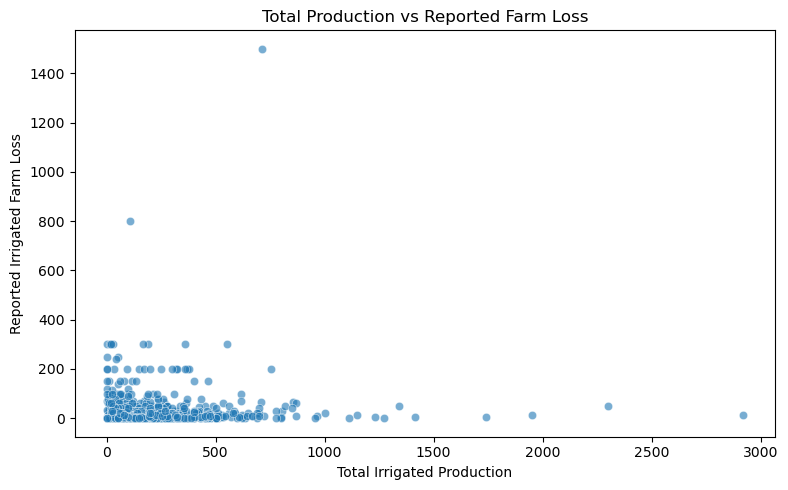

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="totProd_IRG",
    y="farmLoss_kg_IRG",
    alpha=0.6
)

plt.xlabel("Total Irrigated Production")
plt.ylabel("Reported Irrigated Farm Loss")
plt.title("Total Production vs Reported Farm Loss")

plt.tight_layout()
plt.show()

In [20]:
df[[
    "totProd_IRG",
    "farmLoss_kg_IRG"
]].corr()

,totProd_IRG,farmLoss_kg_IRG
totProd_IRG,1.000000,0.039311
farmLoss_kg_IRG,0.039311,1.000000


In [21]:
print("Dataset shape:", model_df.shape)

print("\nMissing values:")
print(model_df.isna().sum().sum())

print("\nTotal production included:")
print("totProd_IRG" in model_df.columns)

Dataset shape: (877, 33)

Missing values:
0

Total production included:
True


In [22]:
model_df.to_csv(
    "tomato_farm_loss_model_v2.csv",
    index=False
)

In [23]:
model_df.to_csv(
    "../data/processed/tomato_farm_loss_model_v2.csv",
    index=False
)